d:\anaconda\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
d:\anaconda\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


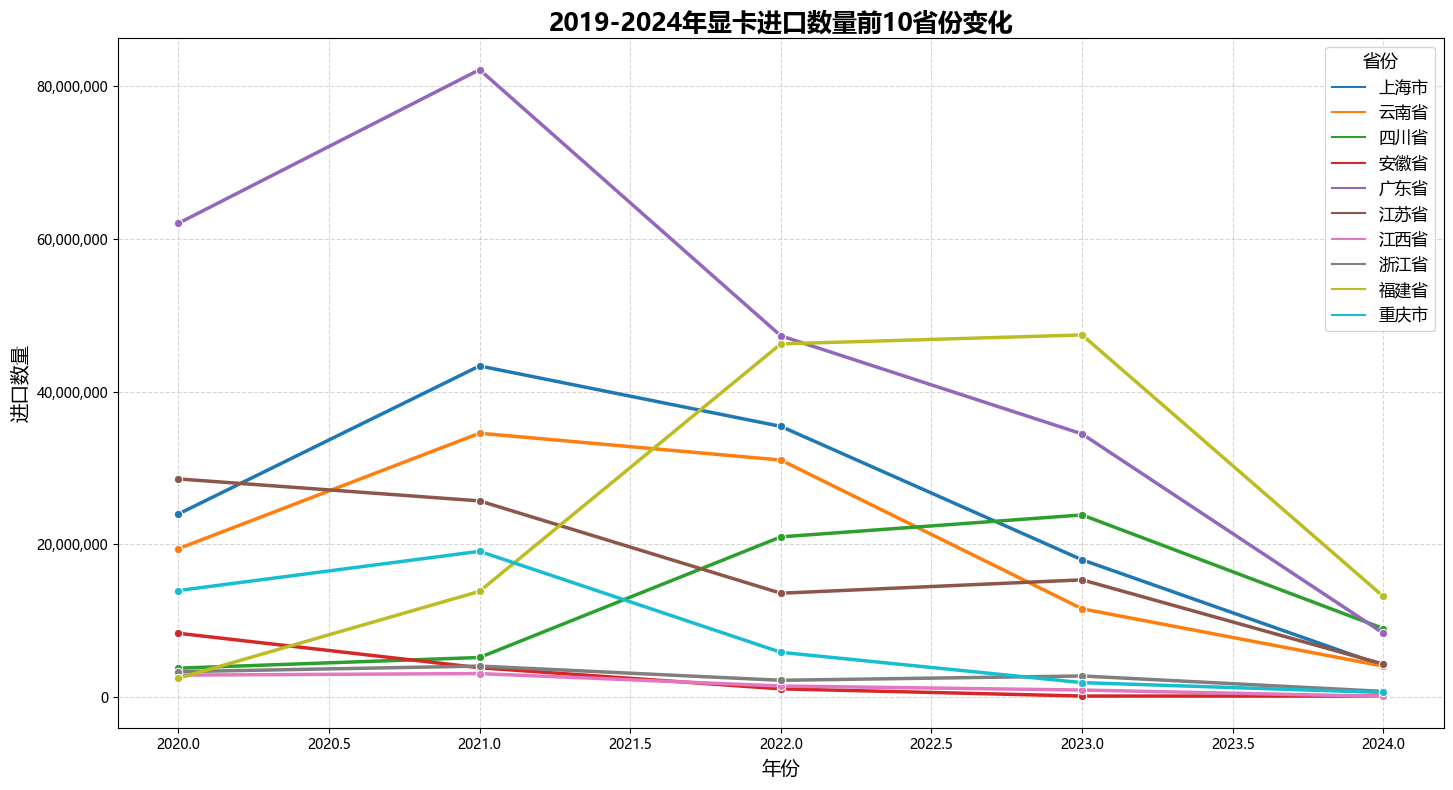

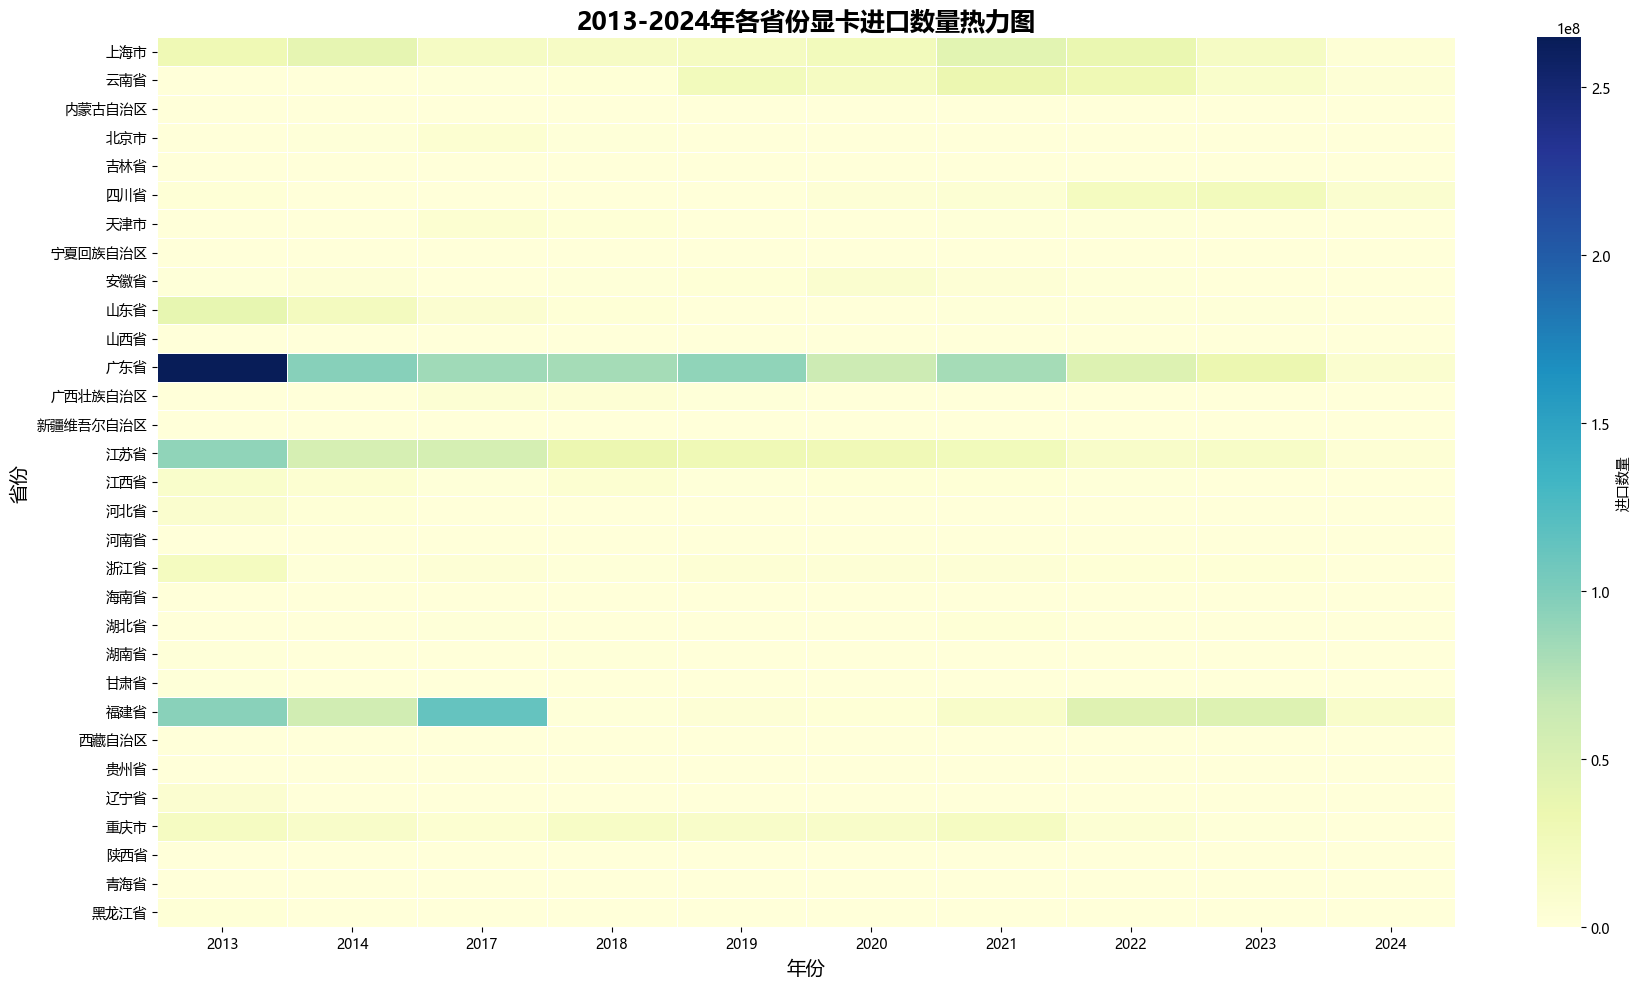

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

# 1. 读取数据
df = pd.read_csv('/home/mw/input/data_total74037403/地区角度数据集/2013-2024各省显卡进口数量.csv')

# 2. 设置全局字体为微软雅黑
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

# 3. 数据预处理
df = df.dropna()
df['年份'] = df['年份'].astype(int)
df['进口数量'] = df['进口数量'].astype(float)

# 4. 选取部分省份和年份进行可视化
recent_years = sorted(df['年份'].unique())[-5:]
top_provinces = (
    df[df['年份'].isin(recent_years)]
    .groupby('省份')['进口数量'].sum()
    .sort_values(ascending=False)
    .head(10)
    .index
)
plot_df = df[df['省份'].isin(top_provinces) & df['年份'].isin(recent_years)]

# 5.可视化：多省份多年份进口数量变化（折线+点+色彩）
plt.figure(figsize=(14, 8))
sns.lineplot(
    data=plot_df,
    x='年份',
    y='进口数量',
    hue='省份',
    marker='o',
    linewidth=2.5,
    palette='tab10'
)
plt.title('2019-2024年显卡进口数量前10省份变化', fontsize=18, weight='bold')
plt.xlabel('年份', fontsize=14)
plt.ylabel('进口数量', fontsize=14)
plt.legend(title='省份', fontsize=12, title_fontsize=13, loc='upper right')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

# 6. 进口数量用科学计数法
plt.gca().yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{int(x):,}'))

plt.show()

# 7. 热力图：各省份各年份进口数量分布
pivot_df = df.pivot_table(index='省份', columns='年份', values='进口数量', fill_value=0)
plt.figure(figsize=(18, 10))
sns.heatmap(
    pivot_df,
    cmap='YlGnBu',
    linewidths=0.5,
    linecolor='white',
    cbar_kws={'label': '进口数量'},
    annot=False
)
plt.title('2013-2024年各省份显卡进口数量热力图', fontsize=18, weight='bold')
plt.xlabel('年份', fontsize=14)
plt.ylabel('省份', fontsize=14)
plt.tight_layout()
plt.show()

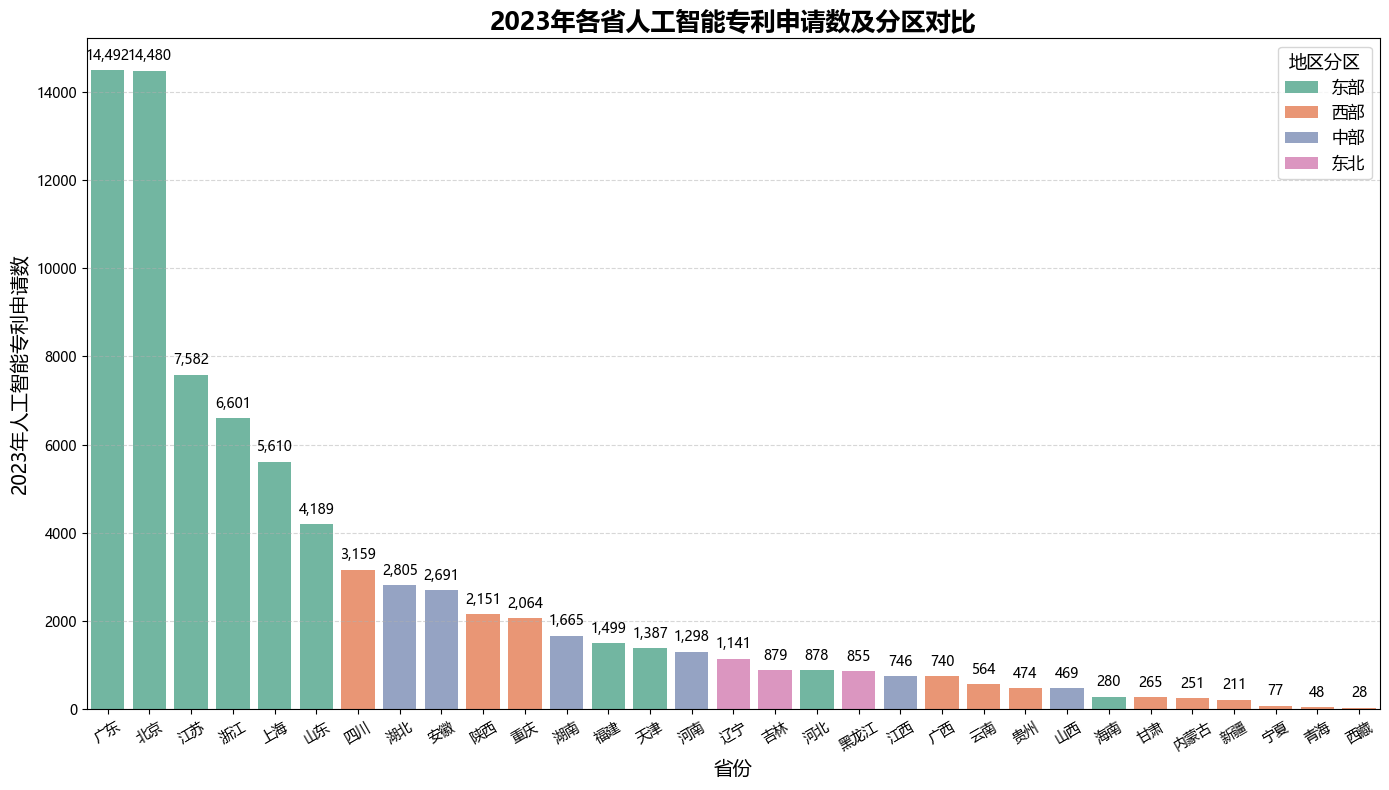

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/home/mw/input/data_total74037403/地区角度数据集/地区.csv')
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

# 构造分区标签
def get_region(row):
    if row['东部地区'] == 1:
        return '东部'
    elif row['中部地区'] == 1:
        return '中部'
    elif row['西部地区'] == 1:
        return '西部'
    elif row['东北部地区'] == 1:
        return '东北'
    else:
        return '其他'

df['地区分区'] = df.apply(get_region, axis=1)
df_sorted = df.sort_values('2023人工智能专利申请数', ascending=False)

plt.figure(figsize=(14, 8))
bar = sns.barplot(
    data=df_sorted,
    x='省份',
    y='2023人工智能专利申请数',
    hue='地区分区',
    dodge=False,
    palette='Set2'
)
plt.title('2023年各省人工智能专利申请数及分区对比', fontsize=18, weight='bold')
plt.ylabel('2023年人工智能专利申请数', fontsize=14)
plt.xlabel('省份', fontsize=14)
plt.xticks(rotation=30)
plt.legend(title='地区分区', fontsize=12, title_fontsize=13, loc='upper right')
plt.grid(axis='y', linestyle='--', alpha=0.5)

# 添加数据标签
for i, v in enumerate(df_sorted['2023人工智能专利申请数']):
    plt.text(i, v + max(df_sorted['2023人工智能专利申请数']) * 0.01, f'{int(v):,}', 
             ha='center', va='bottom', fontsize=10, rotation=0)

plt.tight_layout()
plt.show()

In [5]:
import pandas as pd
import plotly.express as px

df = pd.read_csv('/home/mw/input/data_total74037403/地区角度数据集/人工智能企业数.csv')
df_2023 = df[df['年份'] == 2023].copy()
df_2023['全国'] = '全国'

fig = px.sunburst(
    df_2023,
    path=['全国', '省'],
    values='AI企业数量',
    color='AI企业数量',
    color_continuous_scale='YlGnBu',
    title='2023年各省AI企业数量旭日图',
    width=900,   # 宽度更大
    height=900   # 高度更大
)
fig.update_traces(textinfo="label+value+percent entry", insidetextorientation='radial', textfont_size=18)

fig.update_layout(
    font=dict(family="Microsoft YaHei", size=18),
    plot_bgcolor='#fcfcfc'
)
fig.show()

In [4]:
import pandas as pd
import plotly.express as px

df = pd.read_csv('/home/mw/input/data_total74037403/地区角度数据集/202501生成式人工智能服务已备案信息.csv')
df['备案数量'] = df['备案数量'].astype(int)
df['省份'] = df['省份'].str.replace('\n', '').str.replace(' ', '')

# 渐变色
custom_colors = [
    "#e8f8f5", "#d1f2eb", "#a3e4d7", "#76d7c4", "#48c9b0", "#1abc9c", "#17a589", "#148f77"
]

fig = px.treemap(
    df,
    path=['省份'],
    values='备案数量',
    color='备案数量',
    color_continuous_scale=custom_colors,
    title='各省生成式AI服务备案数量树图',
    height=800
)
fig.update_traces(
    textinfo='label+value+percent entry',
    textfont_size=22,
    marker=dict(line=dict(width=2, color='white'), pad=dict(t=18, l=18, r=18, b=18))
)
fig.update_layout(
    font=dict(family="Microsoft YaHei", size=20),
    plot_bgcolor='#f6fbfa',
    paper_bgcolor='#f6fbfa',
    margin=dict(l=40, r=40, t=90, b=40),
    title=dict(
        font=dict(size=30, family='Microsoft YaHei', color='#145a32'),
        x=0.5,
        y=0.95
    )
)
fig.show()

In [3]:
import pandas as pd
import plotly.graph_objects as go
import numpy as np

df = pd.read_csv('/home/mw/input/data_total74037403/地区角度数据集/地区.csv')
df['2023年（固定）互联网宽带接入用户（万户）'] = df['2023年（固定）互联网宽带接入用户（万户）'].astype(float)
df = df.dropna(subset=['2023年（固定）互联网宽带接入用户（万户）'])

df_sorted = df.sort_values('2023年（固定）互联网宽带接入用户（万户）', ascending=False).reset_index(drop=True)
labels = df_sorted['省份'].tolist()
values = df_sorted['2023年（固定）互联网宽带接入用户（万户）'].values

# 计算每个条的角度
angles = np.linspace(0, 360, len(labels), endpoint=False)

fig = go.Figure()

fig.add_trace(go.Barpolar(
    r=values,
    theta=angles,
    width=[360/len(labels)*0.85]*len(labels),
    marker_color=values,
    marker_colorscale='mint',  
    marker_line_color='white',
    marker_line_width=2,
    opacity=0.95,
    text=labels,
    hovertemplate='<b>%{text}</b><br>宽带用户：%{r:.0f} 万户'
))

fig.update_layout(
    title='2023年各省（固定）互联网宽带接入用户（万户）径向分布条形图',
    font=dict(family="Microsoft YaHei", size=18),
    polar=dict(
        bgcolor='#fafdff',
        radialaxis=dict(showticklabels=False, ticks='', showgrid=False),
        angularaxis=dict(
            tickmode='array',
            tickvals=angles,
            ticktext=labels,
            tickfont=dict(size=15)
        )
    ),
    showlegend=False,
    plot_bgcolor='#fafdff',
    paper_bgcolor='#fafdff',
    margin=dict(l=40, r=40, t=80, b=40)
)
fig.show()